# Lab 15: How to build a customer-support agent over a database

**Notebook 1 of 2: meet chat pages on a café order (solution)**

## Goal

Put a Python function behind a chat page that several people open at the same time, and see what goes wrong when
our code keeps one conversation for everyone. A café bot takes an order from one visitor: *"A flat white with oat
milk, please."* A second visitor, in another browser tab, asks *"What did I order?"* and is told about the first
visitor's coffee. No error appears anywhere. One change, the key we keep each conversation under, fixes it. This
notebook uses a café and no database; notebook 2 puts the Chinook support desk agent behind the same kind of page.

## What you will learn

- How to put a Python function behind a Gradio `ChatInterface`, and what Gradio passes the function on every
  message.
- How to visit a page from code as two separate visitors with `gradio_client`, and read the page's API description
  ("Use via API").
- How to keep a conversation in our own code behind a page, and why one Python list is shared by every visitor.
- How to tell visitors apart with `gr.Request` and its `session_hash`.
- How to keep one conversation per visitor in a dictionary keyed by the visitor's session.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model settings from `models.env`
and takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


The pages in this notebook are drawn by [Gradio](https://www.gradio.app/docs), a library that turns a Python function
into a web page. Two lines come before the import: one hides a progress-bar notice that a
Gradio dependency prints when it is imported, and `GRADIO_ANALYTICS_ENABLED` stops Gradio from sending usage
statistics.

In [2]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # a progress-bar notice printed on import
os.environ["GRADIO_ANALYTICS_ENABLED"] = "False"                   # Gradio sends usage statistics unless told not to

import gradio as gr
print("gradio", gr.__version__)

gradio 6.31.0


---

## Part A: Put a function behind a chat page

A chat page is a web page with a text box. When a visitor sends a message, the page calls a function on our machine
and shows what the function returns. Gradio's [`ChatInterface`](https://www.gradio.app/docs/gradio/chatinterface)
builds that page from one Python function.

We start with a function that calls no model, so that we can see what the page itself does. Gradio calls it once
per message with two arguments:

- `message`: the text the visitor just sent;
- `history`: the conversation shown on that visitor's page so far, one entry per message.

`echo` repeats the message and counts the messages before it. `last_history` keeps a copy of the `history` it
received, only so that this notebook can print it later.

In [3]:
last_history = []


def echo(message, history):
    last_history[:] = history          # a copy for the notebook to print; the page does not need it
    return f"You said \"{message}\". Messages before this one: {len(history)}."


print(echo("A flat white, please.", []))

You said "A flat white, please.". Messages before this one: 0.


Called by hand, `echo` is an ordinary function: we passed an empty history, so it counts 0 messages before this one.

Now we put it behind a page. `gr.ChatInterface(echo)` builds the page; `launch` starts a small web server for it.
The four settings:

- `server_name="127.0.0.1"`: the page answers on this machine only.
- `prevent_thread_lock=True`: the server runs in the background, so the notebook can go on to the next cell.
- `inline=False`: the page is not drawn inside the notebook; we open its address in a browser.
- `quiet=True`: no start-up messages.

We leave out the port, so Gradio takes the first free one from 7860.

In [4]:
page = gr.ChatInterface(echo, title="Café echo")
page.launch(server_name="127.0.0.1", prevent_thread_lock=True, inline=False, quiet=True)
print("the page is at", page.local_url)

the page is at http://127.0.0.1:7860/


The page is running at that address. Open it in your browser and send two messages. The second reply counts 2
messages before it: your first message and the page's reply. Gradio sends the function the whole conversation on
your page every time.

> **[Screenshot placeholder: the Café echo page in a browser after two messages. The second reply ends "Messages
> before this one: 2." The "Use via API" link is at the foot of the page.]**

**Checkpoint A.** `echo` called by hand counts 0 messages before. The page is at `http://127.0.0.1:7860/` (another
port if 7860 was busy), and in a browser the count goes up by two with each message.

---

## Part B: Visit the page from code as two visitors

A browser is one way to visit the page. Code is another, and it lets us save what each visitor saw. At the foot of
every Gradio page, the **Use via API** link opens the page's API page: what the page accepts, what it returns, and
code that calls it from Python or JavaScript.

> **[Screenshot placeholder: the API page of the Café echo page, opened from "Use via API", showing the endpoint
> `/echo`, its parameter `message`, and the Python snippet that uses `gradio_client`.]**

[`gradio_client`](https://www.gradio.app/guides/getting-started-with-the-python-client) is the library that snippet
uses. A `Client` connects to the page the way a new browser tab does: **each `Client` is one visitor**, with a
session of its own. `view_api()` prints the same description as the API page.

In [5]:
from gradio_client import Client

visitor_a = Client(page.local_url, verbose=False)
visitor_a.view_api()

Client.predict() Usage Info
---------------------------
Named API endpoints: 1

 - predict(message, api_name="/echo") -> response
    Parameters:
     - [Textbox] message: str (required)  
    Returns:
     - [Json] response: str | float | bool | list | dict (any valid json) 



One endpoint, `/echo`: the endpoint's name is the function's name. It takes one parameter, `message`, and returns
the reply. `history` is not a parameter: the page keeps each visitor's history itself and passes it to the function.

`predict` sends one message as this visitor and waits for the reply. Visitor A sends two messages; then a second
visitor, B, sends one.

In [6]:
print("A:", visitor_a.predict("A flat white, please.", api_name="/echo"))
print("A:", visitor_a.predict("Make it oat milk.", api_name="/echo"))
print("history the function received for A's second message:")
for entry in last_history:
    print("  ", entry)

visitor_b = Client(page.local_url, verbose=False)
print("B:", visitor_b.predict("What did I order?", api_name="/echo"))

A: You said "A flat white, please.". Messages before this one: 0.
A: You said "Make it oat milk.". Messages before this one: 2.
history the function received for A's second message:
   {'role': 'user', 'content': 'A flat white, please.'}
   {'role': 'assistant', 'content': 'You said "A flat white, please.". Messages before this one: 0.'}
B: You said "What did I order?". Messages before this one: 0.


Read it in three steps:

1. **A's first message** comes with an empty history: 0 messages before it.
2. **A's second message** comes with 2: A's first message and the page's reply to it. The history is a list of
   dictionaries, one per message, each with a `role` (`user` for the visitor, `assistant` for the page) and its
   `content`.
3. **B's message** comes with 0. B is a new visitor, so B's history starts empty.

**Gradio keeps a separate history for each visitor.** The page does not mix visitors. Keep that in mind for Part C.

⚠️ Only one page can use a port at a time, and a page keeps running until it is closed. Each part of this notebook
closes its page when it is done.

In [7]:
page.close()

Closing server running on port: 7860


**Checkpoint B.** `view_api()` lists one endpoint, `/echo`, with one parameter, `message`. Visitor A's two messages
count 0 and then 2 messages before them; visitor B's first message counts 0.

---

## Part C: Let a model take the order, with one list for the whole page

Now a café bot: a model that takes orders. It needs the conversation so far, so that it can answer *"What did I
order?"*.

The page already passes `history`, so why keep the conversation ourselves? Because an agent keeps more than the page
shows. On every turn an agent sends the model its tool calls and their results as well, and the page shows none of
them. So a page with an agent behind it keeps the conversation in our own code. The café bot does the same, without
tools, so that the conversation is the only thing to watch.

We keep it the way a notebook keeps a conversation: **one Python list of messages**. Each call:

1. appends the visitor's message to the list;
2. sends the whole list to the model with the Chat Completions API;
3. appends the model's reply to the list and returns it.

The model call passes `reasoning_effort=EFFORT or omit`: the effort from `models.env`, or no effort at all when the
setting is empty. `take_order` takes `history` because Gradio passes it, and does not use it.

In [8]:
from openai import OpenAI, omit

client = OpenAI()
SYSTEM = {"role": "system", "content": "You take orders at a small café. Reply in one or two short sentences."}

# One list of messages for the whole page: the system message, then every turn in order
messages = [SYSTEM]


def take_order(message, history):
    messages.append({"role": "user", "content": message})
    response = client.chat.completions.create(model=MODEL, messages=messages, reasoning_effort=EFFORT or omit)
    reply = response.choices[0].message.content
    messages.append({"role": "assistant", "content": reply})
    return reply

The café page, and visitor A's order:

In [9]:
page = gr.ChatInterface(take_order, title="Café")
page.launch(server_name="127.0.0.1", prevent_thread_lock=True, inline=False, quiet=True)

visitor_a = Client(page.local_url, verbose=False)
print("A:", visitor_a.predict("A flat white with oat milk, please.", api_name="/take_order"))

A: Sure—a flat white with oat milk. Anything else?


The bot took A's order. Now visitor B opens the page in another tab and asks *"What did I order?"*. B has sent
nothing before. **Predict:** what will B be told?

In [10]:
visitor_b = Client(page.local_url, verbose=False)
print("B:", visitor_b.predict("What did I order?", api_name="/take_order"))

print("\nthe list our code keeps:")
for m in messages:
    print(f"  {m['role']:9} | {m['content']}")
page.close()

B: A flat white with oat milk.

the list our code keeps:
  system    | You take orders at a small café. Reply in one or two short sentences.
  user      | A flat white with oat milk, please.
  assistant | Sure—a flat white with oat milk. Anything else?
  user      | What did I order?
  assistant | A flat white with oat milk.
Closing server running on port: 7860


B was told about A's coffee: *A flat white with oat milk.* B never ordered anything, and no error appeared anywhere.

The list shows why. It holds the system message, A's order, the bot's reply, then B's question and the reply to it:
**both visitors' messages in one list.** One Python program serves every visitor of the page, and `messages` is one
object in that program, so every call appends to the same list. When B asked, the model received A's order as the
conversation so far and answered from it.

Gradio kept the two visitors apart (Part B: B's history was empty). Our code mixed them.

> **[Screenshot placeholder: two browser tabs side by side on the Café page. Left tab: "A flat white with oat milk,
> please." and the bot's reply. Right tab: "What did I order?" and a reply naming the flat white with oat milk.]**

At a café this is a mix-up at the counter. At a support desk the second visitor would be told about another
customer's account.

**Checkpoint C.** Visitor B, who never ordered, is told about a flat white with oat milk, and the list holds five
messages: the system message and both visitors' turns.

---

## Part D: Tell visitors apart with `gr.Request`

To keep the visitors apart, the function must know which visitor sent each message. Gradio can tell it: add a
parameter with the type hint [`gr.Request`](https://www.gradio.app/docs/gradio/request), and Gradio passes in the
request on every call. Its `session_hash` is a random id for one visitor's open page. A `Client` keeps the id of its
own session in `session_hash` too, so we can compare the two.

In [11]:
def whoami(message, history, request: gr.Request):
    return f"Your session: {request.session_hash[:8]}"


page = gr.ChatInterface(whoami)
page.launch(server_name="127.0.0.1", prevent_thread_lock=True, inline=False, quiet=True)

visitor_a, visitor_b = Client(page.local_url, verbose=False), Client(page.local_url, verbose=False)
print("A:", visitor_a.predict("hello", api_name="/whoami"), "|", visitor_a.predict("again", api_name="/whoami"))
print("B:", visitor_b.predict("hello", api_name="/whoami"))
print("the clients' own ids:", visitor_a.session_hash[:8], "and", visitor_b.session_hash[:8])
page.close()

A: Your session: e972b067 | Your session: e972b067
B: Your session: 8bd08fc8
the clients' own ids: e972b067 and 8bd08fc8


Closing server running on port: 7860


Visitor A gets the same id for both messages, and visitor B gets another (we print the first 8 characters of each).
The ids the page received match the ids the two clients hold: **one session per visitor.**

Gradio makes a new id each time a page is loaded, so a visitor who reloads the browser tab gets a new one.

**Checkpoint D.** A's two messages show one id; B's shows a different id; each matches its client's `session_hash`.

---

## Part E: Keep one conversation per visitor

The fix changes one thing: which list a message goes into. Instead of one list, we keep a dictionary that maps each
visitor's session id to that visitor's own list.

`conversations.setdefault(key, [SYSTEM])` returns the list stored under `key`; when there is none yet, it stores
`[SYSTEM]` under that key first and returns it. So a visitor's first message starts a new list, and every later
message from the same visitor finds it again. The rest of `take_order` is unchanged.

In [12]:
# One list of messages per visitor, found by the visitor's session id
conversations = {}


def take_order(message, history, request: gr.Request):
    messages = conversations.setdefault(request.session_hash, [SYSTEM])
    messages.append({"role": "user", "content": message})
    response = client.chat.completions.create(model=MODEL, messages=messages, reasoning_effort=EFFORT or omit)
    reply = response.choices[0].message.content
    messages.append({"role": "assistant", "content": reply})
    return reply

Two new visitors on a fresh page (two new clients, so two new session ids). A orders, B asks what they ordered,
then A asks the same.

In [13]:
page = gr.ChatInterface(take_order, title="Café")
page.launch(server_name="127.0.0.1", prevent_thread_lock=True, inline=False, quiet=True)

visitor_a, visitor_b = Client(page.local_url, verbose=False), Client(page.local_url, verbose=False)
print("A:", visitor_a.predict("A flat white with oat milk, please.", api_name="/take_order"))
print("B:", visitor_b.predict("What did I order?", api_name="/take_order"))
print("A:", visitor_a.predict("What did I order?", api_name="/take_order"))

print("\nconversations kept:")
for session_id, kept in conversations.items():
    print(f"  {session_id[:8]}: {len(kept)} messages")

A: Sure—a flat white with oat milk. Anything else?


B: I don’t see an order in our conversation yet.


A: A flat white with oat milk.

conversations kept:
  db29cc5e: 5 messages
  c609801c: 3 messages


This time B is told *I don’t see an order in our conversation yet.*, and A still gets their order back: *A flat white with oat milk.*

The dictionary holds two conversations, one per session id: A's with 5 messages (the system message and two turns)
and B's with 3 (the system message and one turn).

**Key lesson:** the model reads the messages stored under the key we choose. A fixed key, or one list, gives every
visitor the same conversation; the visitor's session id gives each their own.

Both versions in one picture: at the top Part C's one list, below it Part E's list per visitor. The lime boxes
are what our code keeps; the model (ink) reads whichever list it is sent.

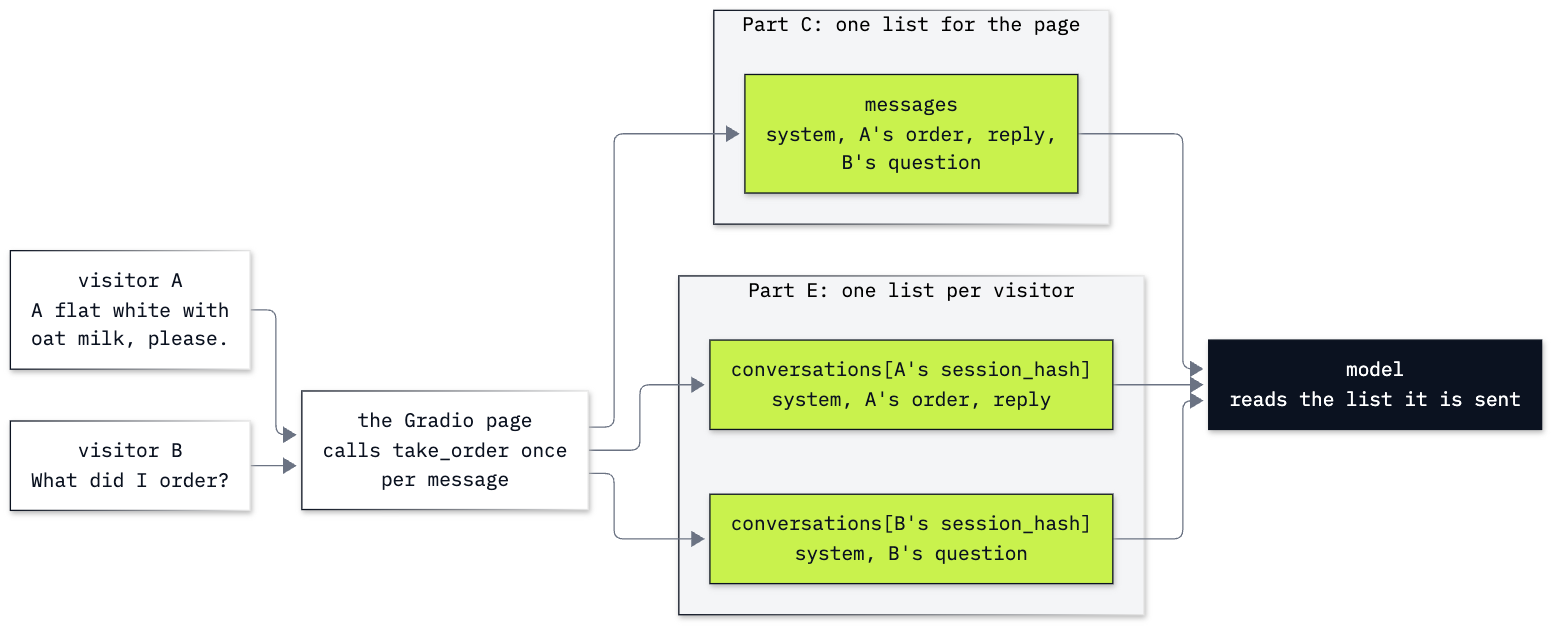

In [14]:
from IPython.display import Image

Image(filename="../resources/lab15_one_list_or_per_visitor.png", width=760)

Two limits of this version:

- **The conversations are kept in memory only.** When the program stops, they are gone. Notebook 2 keeps them in a
  file.
- **A reload starts over.** A new page load is a new session id, so the old conversation is no longer found. A real
  application keys conversations by who is signed in rather than by the open page.

The page is still running. Open its address in two browser tabs (or two different browsers), order in one and ask
*"What did I order?"* in the other.

In [15]:
print("try it in your browser:", page.local_url)

try it in your browser: http://127.0.0.1:7860/


When you are done, run the next cell to close the page. Under **Run All** the next cell closes it at once, so run the
cells one at a time up to here if you want to keep it open.

In [16]:
page.close()

Closing server running on port: 7860


**Checkpoint E.** B, who never ordered, is told there is no order yet; A is told their flat white with oat milk; the
dictionary holds two conversations, 5 messages for A and 3 for B.

---

## What you can do now

- Put a Python function behind a Gradio `ChatInterface`, and say what Gradio passes it on each message (Part A).
- Visit a page from code as two visitors with `gradio_client`, and read its API description with `view_api()` or
  the "Use via API" link (Part B).
- Explain why one list in our code behind a page is shared by every visitor, and spot it from what a second visitor
  is told (Part C).
- Tell visitors apart with `gr.Request` and `request.session_hash` (Part D).
- Keep one conversation per visitor in a dictionary keyed by the session id (Part E).

## Challenge

The tasks, as set in the notebook:

1. **Let a visitor start over.** The message `start over` replaces this visitor's list with `[SYSTEM]` and replies
   *New order.* without calling the model.
2. **Give every visitor a table number.** The first visitor to write sits at table 1, the next at table 2, and each
   visitor's system message names their table.

### Solution 1: start over

The only new lines come before the model call: when the message is exactly `start over`, we store a new list under
this visitor's key and return. Any other visitor's list is not touched, because we only change the entry under
`request.session_hash`.

In [17]:
conversations = {}


def take_order(message, history, request: gr.Request):
    if message.strip().lower() == "start over":
        conversations[request.session_hash] = [SYSTEM]
        return "New order."
    messages = conversations.setdefault(request.session_hash, [SYSTEM])
    messages.append({"role": "user", "content": message})
    response = client.chat.completions.create(model=MODEL, messages=messages, reasoning_effort=EFFORT or omit)
    reply = response.choices[0].message.content
    messages.append({"role": "assistant", "content": reply})
    return reply


page = gr.ChatInterface(take_order, title="Café")
page.launch(server_name="127.0.0.1", prevent_thread_lock=True, inline=False, quiet=True)

visitor_a, visitor_b = Client(page.local_url, verbose=False), Client(page.local_url, verbose=False)
print("A:", visitor_a.predict("A flat white with oat milk, please.", api_name="/take_order"))
print("B:", visitor_b.predict("A cappuccino, please.", api_name="/take_order"))
print("A:", visitor_a.predict("start over", api_name="/take_order"))
print("A:", visitor_a.predict("What did I order?", api_name="/take_order"))
print("B:", visitor_b.predict("What did I order?", api_name="/take_order"))
page.close()

A: Sure—one flat white with oat milk. Anything else?


B: Sure—one cappuccino, coming right up. Anything else?
A: New order.


A: You haven’t ordered anything yet.


B: You ordered a cappuccino.
Closing server running on port: 7860


After `start over`, A is told *You haven’t ordered anything yet.*, and B still gets the cappuccino: *You ordered a cappuccino.*

### Solution 2: a table number per visitor

`next_table` is shared on purpose: every visitor takes the next number from it. `global next_table` lets
`take_order` change that counter; without it, Python treats `next_table` as a new local name, and
`next_table += 1` raises `UnboundLocalError`. `tables` maps each session id to its
table number, and the visitor's list starts with a system message that names the table. Both are only touched the
first time a visitor writes, when the session id is not in `tables` yet.

In [18]:
conversations = {}
tables = {}
next_table = 1


def take_order(message, history, request: gr.Request):
    global next_table
    key = request.session_hash
    if key not in tables:
        tables[key] = next_table
        next_table += 1
        seat = {"role": "system", "content": SYSTEM["content"] + f" This guest sits at table {tables[key]}."}
        conversations[key] = [seat]
    messages = conversations[key]
    messages.append({"role": "user", "content": message})
    response = client.chat.completions.create(model=MODEL, messages=messages, reasoning_effort=EFFORT or omit)
    reply = response.choices[0].message.content
    messages.append({"role": "assistant", "content": reply})
    return reply


page = gr.ChatInterface(take_order, title="Café")
page.launch(server_name="127.0.0.1", prevent_thread_lock=True, inline=False, quiet=True)

visitor_a, visitor_b = Client(page.local_url, verbose=False), Client(page.local_url, verbose=False)
print("A:", visitor_a.predict("A flat white with oat milk, please.", api_name="/take_order"))
print("B:", visitor_b.predict("A cappuccino, please.", api_name="/take_order"))
print("A:", visitor_a.predict("Which table am I at?", api_name="/take_order"))
print("B:", visitor_b.predict("Which table am I at?", api_name="/take_order"))
print("tables:", {key[:8]: number for key, number in tables.items()})
page.close()

A: One flat white with oat milk for table 1. Anything else?


B: Certainly—a cappuccino for table 2.


A: You’re at table 1.


B: You’re at table 2.
tables: {'5bb87ae4': 1, '5fa05275': 2}
Closing server running on port: 7860


A is told *You’re at table 1.* and B *You’re at table 2.* The table counter is shared by every visitor, as a café needs it to
be; each conversation stays with its own visitor.

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| the page's address ends in `:7861` or higher, not `:7860` | a page started earlier in this kernel is still running (a cell run twice, or a cell that stopped before `page.close()`), so Gradio took the next free port | `gr.close_all()` closes every page this kernel started; then run the cell again |
| `OSError: Cannot find empty port in range: 7860-7860.`, followed by a hint about `server_port` | `launch` was given `server_port=7860` and another page holds that port | leave `server_port` out, as this notebook does, or run `gr.close_all()` |
| `AppError: The upstream Gradio app has raised an exception but has not enabled verbose error reporting. To enable, set show_error=True in launch().` | our page function raised an error; the client sees only this line | read the error printed above it in the notebook, or launch with `show_error=True` to send the message to the client |
| the address does not open in your browser on a remote VM or in Codespaces | `127.0.0.1` is the remote machine, not yours | open the address VS Code forwards for the port (its **Ports** panel; add the port there if it is missing) |

## Resources

- [Gradio: `ChatInterface`](https://www.gradio.app/docs/gradio/chatinterface): the function's `message` and
  `history`, and the page's other settings
- [Gradio: creating a chatbot fast](https://www.gradio.app/guides/creating-a-chatbot-fast): chat functions and the
  `history` format
- [Gradio: `Request`](https://www.gradio.app/docs/gradio/request): `session_hash` and the other attributes of a
  request
- [Gradio: the API page](https://www.gradio.app/guides/view-api-page): what the "Use via API" link shows
- [Gradio: the Python client](https://www.gradio.app/guides/getting-started-with-the-python-client): `Client`,
  `view_api`, `predict` and `submit`
- [OpenAI: Chat Completions API reference](https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create):
  `messages` and the reply

Next: [notebook 2, the support desk agent behind a chat page](../15b_chat_pages_at_the_desk.ipynb). Back to
[the lab's README](../README.md).